In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import data_loaders
import miscellaneous
from rs_algorithm.models import RegressionBasedBPEModel
from rs_algorithm.models import AdaptiveRepresentation
from dl_trainer import Trainer, split_collate

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [7]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [8]:
try:
    ds_train = data_model.get_bpr_dataset()
    smaller_matrix = miscellaneous.keyed_cache("kuairec_smaller_matrix", lambda: data_model.subsample_specimen('small', 10000))
except:
    traceback.print_exc()

In [8]:
try:
    for col in data_model.user_features.columns:
        print(col)
except:
    traceback.print_exc()

user_active_degree_UNKNOWN
user_active_degree_full_active
user_active_degree_high_active
user_active_degree_middle_active
follow_user_num
follow_user_num_range_(0,10]
follow_user_num_range_(10,50]
follow_user_num_range_(100,150]
follow_user_num_range_(150,250]
follow_user_num_range_(250,500]
follow_user_num_range_(50,100]
follow_user_num_range_0
follow_user_num_range_500+
fans_user_num
fans_user_num_range_0
fans_user_num_range_[1,10)
fans_user_num_range_[10,100)
fans_user_num_range_[100,1k)
fans_user_num_range_[1k,5k)
fans_user_num_range_[1w,10w)
fans_user_num_range_[5k,1w)
friend_user_num
friend_user_num_range_0
friend_user_num_range_250+
friend_user_num_range_[1,5)
friend_user_num_range_[120,250)
friend_user_num_range_[30,60)
friend_user_num_range_[5,30)
friend_user_num_range_[60,120)
register_days
register_days_range_15-30
register_days_range_181-365
register_days_range_31-60
register_days_range_366-730
register_days_range_61-90
register_days_range_730+
register_days_range_91-180
on

In [9]:
try:
    for col in data_model.user_features.columns:
        dat = data_model.user_features[col]
        print(f"{col:40s}", dat.min(), dat.max(), dat.mean(), dat.std())
except:
    traceback.print_exc()

user_active_degree_UNKNOWN               False True 0.01644370122630992 0.12718317512777091
user_active_degree_full_active           False True 0.8489409141583054 0.35813141670387977
user_active_degree_high_active           False True 0.13071348940914157 0.3371102337177617
user_active_degree_middle_active         False True 0.0039018952062430325 0.0623475109067581
follow_user_num                          -0.4626210845907247 4.460678077746371 3.762628756812125e-17 1.0
follow_user_num_range_(0,10]             False True 0.27020624303233 0.44409718852811947
follow_user_num_range_(10,50]            False True 0.3068561872909699 0.4612213260245352
follow_user_num_range_(100,150]          False True 0.059921962095875136 0.23735874032692625
follow_user_num_range_(150,250]          False True 0.06577480490523968 0.24790531295838195
follow_user_num_range_(250,500]          False True 0.0636845039018952 0.24420708117726586
follow_user_num_range_(50,100]           False True 0.12402452619843925 0

In [10]:
try:
    for i, d in zip(range(1), ds_train):
        print("Sample")
        print(len(d))
        print(len(d[0]), type(d[0][0]), type(d[0][1]), type(d[0][2]), type(d[0][3]), type(d[0][4]), type(d[0][5]))
        print(len(d[1]), type(d[1][0]), type(d[1][1]))
        ...
except:
    traceback.print_exc()

Sample
2
6 <class 'numpy.int64'> <class 'numpy.ndarray'> <class 'numpy.int64'> <class 'numpy.ndarray'> <class 'numpy.int64'> <class 'numpy.ndarray'>
2 <class 'numpy.float32'> <class 'numpy.float32'>


In [9]:
try:
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=1024, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=1024, id2idx=iid2idx)
    model = RegressionBasedBPEModel(user_model, item_model)
except:
    traceback.print_exc()

In [12]:
try:
    ...
except:
    traceback.print_exc()

In [47]:
def loss_fn_all(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds

    # is it really necessary?
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)

    # regression
    reg_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)

    # ranking
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))

    # weight by preference strength
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()

    return reg_loss + rank_loss


def loss_fn_al_v2(preds, truth, lambda_reg=1.0, lambda_rank=1.0):
    s_pos, s_neg = preds
    r_pos, r_neg = truth

    r_pos_t = torch.log1p(r_pos)
    r_neg_t = torch.log1p(r_neg)

    reg_loss = F.mse_loss(s_pos, r_pos_t) + F.mse_loss(s_neg, r_neg_t)

    diff = s_pos - s_neg
    rank_loss = F.softplus(-diff)  # = log(1 + exp(-(s_pos - s_neg)))

    with torch.no_grad():
        weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))

    rank_loss = (rank_loss * weight).mean()

    loss = lambda_reg * reg_loss + lambda_rank * rank_loss

    return loss


def loss_fn_mse_only(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg, _ = preds
    # r_pos = torch.log1p(r_pos)
    # r_neg = torch.log1p(r_neg)
    reg_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)
    return reg_loss


def loss_fn_ranking_only(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()
    return rank_loss


def loss_fn_cls(preds, truth):
    # Why does it CAUSES NaNs everywhere
    r_pos, r_neg, _ = preds
    r_pos = torch.log1p(r_pos - 0.75)
    r_neg = torch.log1p(r_neg - 0.75)
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    r_pos, r_neg = torch.sigmoid((r_pos)), torch.sigmoid((r_neg))
    print(r_pos, r_neg, s_pos, s_neg)
    cls_loss = F.binary_cross_entropy(r_pos, s_pos) + F.binary_cross_entropy(r_neg, s_neg)
    return cls_loss


def l2_reg(*tensors):
    return sum((t ** 2).sum() for t in tensors)


def loss_fn_cls_mse(preds, truth):
    r_pos, r_neg, _ = preds
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    r_pos, r_neg = torch.sigmoid(2 * (r_pos - 0.75)), torch.sigmoid(2 * (r_neg - 0.75))
    cls_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)
    return cls_loss


def id_embed_regularizer(preds, lbd=0.0001):
    _, _, (uie, piie, niie) = preds
    return lbd * l2_reg(uie, piie, niie)

In [14]:
loss = None

In [52]:
try:
    trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(ds_train, batch_size=8192),
        # val_dataloader=DataLoader(ds_test, batch_size=1024),
        # criterion=loss_fn_cls_mse,
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0001),
        regularization=id_embed_regularizer,
        epochs=1,
        # dataset_fraction=10,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [49]:
# try:
#     trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
# except:
#     traceback.print_exc()

In [53]:
try:
    trainer.train()
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 416.37    TTS: 6.93    ETA: 837.95
Epoch:  0/ 1    Train Loss: 1502.86    TTS: 13.47    ETA: 808.33
Epoch:  0/ 1    Train Loss: 466.21    TTS: 20.07    ETA: 796.16
Epoch:  0/ 1    Train Loss: 675.93    TTS: 26.66    ETA: 786.41
Epoch:  0/ 1    Train Loss: 1016.06    TTS: 33.24    ETA: 777.83
Epoch:  0/ 1    Train Loss: 798.25    TTS: 39.83    ETA: 770.11
Epoch:  0/ 1    Train Loss: 458.45    TTS: 46.50    ETA: 763.99
Epoch:  0/ 1    Train Loss: 414.32    TTS: 53.08    ETA: 756.39
Epoch:  0/ 1    Train Loss: 588.76    TTS: 59.71    ETA: 749.64
Epoch:  0/ 1    Train Loss: 709.71    TTS: 66.59    ETA: 745.86
Epoch:  0/ 1    Train Loss: 620.39    TTS: 73.15    ETA: 738.20
Epoch:  0/ 1    Train Loss: 461.74    TTS: 79.81    ETA: 731.60
Epoch:  0/ 1    Train Loss: 386.36    TTS: 86.44    ETA: 724.81
Epoch:  0/ 1    Train Loss: 428.90    TTS: 93.07    ETA: 717.94
Epoch:  0/ 1    Train Loss: 518.93    TTS: 99.71    ETA: 711.25
Epoch:  0/ 1    Train Loss: 524.39    T

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
2


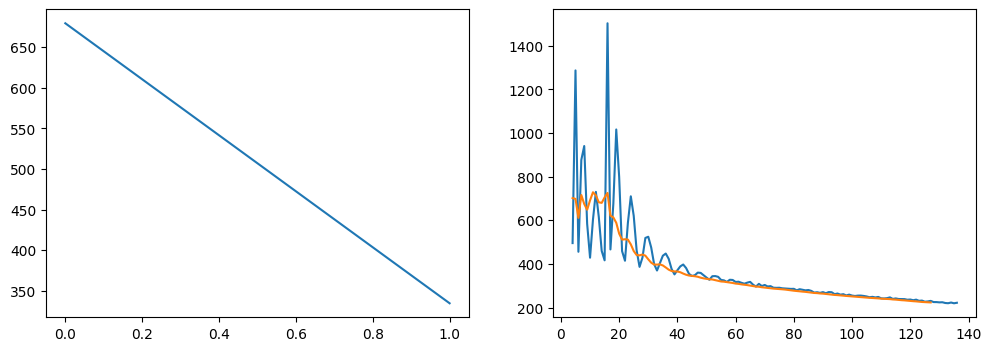

In [56]:
try:
    def running_average(arr, window=10):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(trainer.loss['train'])
    axs[1].plot(trainer.loss['batch.train'])
    axs[1].plot(running_average(trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [161]:
trainer.loss['train']

[np.float64(0.7604748877612028)]

In [151]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(DataLoader(ds_test, batch_size=1024)))
        preds = model(uid, uft, pid, pif, nid, nif)
        print(loss_fn_cls_mse(preds, truth, 0.0))
except:
    traceback.print_exc()

tensor(0.8010)


In [39]:
try:
    timers = trainer.timer.timers
    for key in timers.keys():
        print(f"{key:30s}", timers[key].average)
except:
    traceback.print_exc()

train                          874.6187230000069
_train_step                    874.5929134999969
train_dataloader               6.195387512294682
batch                          0.9733937606559594


In [ ]:
# train                          76.00564779999695
# _train_step                    0.551101999997627
# train_dataloader               34.60407495370188
# batch                          0.03544427272704938
# _validate_step                 75.40476679999847
# val_batch                      0.03169888556699662

In [57]:
try:
    trainer.save_model("embedder_v4_mse_only")
    trainer.save_loss("embedder_v4_mse_only")
except:
    traceback.print_exc()

In [102]:
try:
    with torch.no_grad():
        model.eval()
        (uid, uft, pid, pif, nid, nif), (pr, nr) = next(iter(ds_test))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        sample = model(uid, uft, pid, pif, nid, nif)
except:
    traceback.print_exc()

In [107]:
try:
    with torch.no_grad():
        print(sample)
        print(pr, nr)

        ue, ub = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)
        print((ue * pie).sum())
        print((ue * nie).sum())
except:
    traceback.print_exc()

(tensor([35.1004]), tensor([-15.7325]))
0.8890963 0.6585579
tensor(34.7562)
tensor(-14.1061)


In [37]:
try:
    with torch.no_grad():
        pf, pb = item_model(pid, pif)
        nf, nb = item_model(nid, nif)
        print(pf, pb)
        print(nf, nb)
except:
    traceback.print_exc()

tensor([[ 0.6175,  0.0037,  0.4421,  ...,  1.6565,  0.8547, -0.1677]]) tensor([1.7999])
tensor([[-0.4605,  0.1314,  0.3111,  ..., -0.0321,  1.0296, -0.3057]]) tensor([-1.7498])


In [39]:
try:
    with torch.no_grad():
        print((pf * nf).sum(dim=1))
except:
    traceback.print_exc()

tensor([131.7666])


In [111]:
try:
    r = data_model.ratings
    # print(r['user_id'].unique())
    print(r[(r['user_id'] == 2246)].sort_values('rating'))
    # 9178 739
except:
    traceback.print_exc()

        user_id  item_id    rating                     time
176853     2246     8804  0.000000  2020-08-04 00:02:53.945
633503     2246      867  0.000000  2020-08-03 23:02:40.888
441860     2246     2611  0.003231  2020-08-08 11:35:21.442
973690     2246     4364  0.004699  2020-08-09 05:36:08.837
82854      2246     9824  0.014148                      NaN
...         ...      ...       ...                      ...
668401     2246     2354  1.872266   2020-07-18 18:39:44.35
273780     2246     9907  1.912010  2020-07-23 05:52:44.662
174172     2246     3950  2.107771   2020-07-18 05:26:25.82
119878     2246     6985  3.040702  2020-07-13 11:07:49.141
105908     2246     2343  5.141892   2020-07-18 18:28:52.98

[708 rows x 4 columns]


In [173]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 2354
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 2343
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub, uei, ua = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        ae, ab, aei, aa = item_model(torch.tensor([aii], dtype=torch.long), torch.tensor(aif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        be, bb, bei, ba = item_model(torch.tensor([bii], dtype=torch.long), torch.tensor(bif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        ce, cb, cei, ca = item_model(torch.tensor([cii], dtype=torch.long), torch.tensor(cif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        print("ae * be", (ae * be).sum(dim=1))
        print("ae * ce", (ae * ce).sum(dim=1))
        print("ue * ae", (ue * ae).sum(dim=1))
        print("ue * be", (ue * be).sum(dim=1))
        print("ue * ce", (ue * ce).sum(dim=1))
        print("ua", ua)
        print("||ue|| ", (ue ** 2).sum() ** 0.5)
        print("||uei||", (uei ** 2).sum() ** 0.5)
        print("||uef||", ((ue - uei) ** 2).sum() ** 0.5)
        # print(ae, be)
except:
    traceback.print_exc()

ae * be tensor([343.5952])
ae * ce tensor([105.5864])
ue * ae tensor([413.4880])
ue * be tensor([155.2640])
ue * ce tensor([-301.4289])
ua tensor([[0.4788]])
||ue||  tensor(32.1164)
||uei|| tensor(31.0921)
||uef|| tensor(45.2167)


In [113]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 2354
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 2343
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float))
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        be, bb = item_model(None, torch.tensor(bif[None, :], dtype=torch.float))
        ce, cb = item_model(None, torch.tensor(cif[None, :], dtype=torch.float))
        print((ae * be).sum(dim=1))
        print((ae * ce).sum(dim=1))
        print((ue * ae).sum(dim=1))
        print((ue * ce).sum(dim=1))
        # print(ae, be)
except:
    traceback.print_exc()

tensor([630.9227])
tensor([495.7508])
tensor([89.0869])
tensor([-44.3784])


In [73]:
try:
    with torch.no_grad():
        ae, ab = item_model(torch.tensor([aii], dtype=torch.long), torch.tensor(aif[None, :], dtype=torch.float))
        print((ae ** 2).sum())
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        print((ae ** 2).sum())
except:
    traceback.print_exc()

tensor(525.7579)
tensor(1013.2061)


In [115]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 10677
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 10693
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float))
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        be, bb = item_model(None, torch.tensor(bif[None, :], dtype=torch.float))
        ce, cb = item_model(None, torch.tensor(cif[None, :], dtype=torch.float))
        print((ae * be).sum(dim=1))
        print((ae * ce).sum(dim=1))
        print((ue * ae).sum(dim=1))
        print((ue * ce).sum(dim=1))
        # print(ae, be)
except:
    traceback.print_exc()

tensor([1011.7667])
tensor([588.9796])
tensor([-23.0292])
tensor([-44.3784])


In [114]:
try:
    i = data_model.item_features
    # print(i[(i['first_level_category_name_其他']==1)&(i['second_level_category_name_休闲舞蹈']==1)].shape)
    print(i[(i['first_level_category_name_其他'] == 1) & (i['second_level_category_name_生活泛拍'] == 1)])
except:
    traceback.print_exc()

       first_level_category_name_UNKNOWN  first_level_category_name_三农  \
14                                 False                         False   
22                                 False                         False   
27                                 False                         False   
44                                 False                         False   
59                                 False                         False   
...                                  ...                           ...   
10677                              False                         False   
10693                              False                         False   
10696                              False                         False   
10702                              False                         False   
10710                              False                         False   

       first_level_category_name_二次元  first_level_category_name_亲子  \
14                             False     

In [49]:
i[(i['first_level_category_name_其他'] == 1)]

,first_level_category_name_UNKNOWN,first_level_category_name_三农,first_level_category_name_二次元,first_level_category_name_亲子,first_level_category_name_人文,first_level_category_name_健康,first_level_category_name_健身,first_level_category_name_其他,first_level_category_name_军事,first_level_category_name_喜剧,...,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30
14,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
22,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
24,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
27,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
44,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10693,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10696,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10702,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10705,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
